# MidiTranslator — interleaved midiseq2 ⇄ Lilylet, model validation

Loads `configs/midi-translator-interleaved-lilylet.yaml` and validates `MidiTranslator` /
`MidiTranslatorLoss` against the `InterleavedSeq2` batch. The model is the same decoder-only stack as
`midiTranslator_validation.ipynb` and `midiTranslator_irregular_to_lilylet_validation.ipynb`. What
changes is the sequence: instead of one source half and one target half, the crop is cut into
**played-measure units** and the two languages alternate, source first:

```
<bos>? %style\n ... \n  src1 <sep> tar1 <eom>  src2 <sep> tar2 <eom>  ...  srcN <sep> tarN <eom>
└───── context ──────┘ └ ctx ┘     └supervised┘ └ ctx ┘    └supervised┘        └supervised┘
```

What this notebook checks that the mixed `Seq2Seq2` notebook cannot:

- **Many supervised runs per row.** `target_mask` is no longer a tail; it is one run per unit, each
  `tar <eom>`, and each run's first label is predicted from that unit's `<sep>`. The next unit's source
  is context again, so the mask switches off right after every `<eom>`.
- **No `<eos>` at all.** `<eom>` is the only stop signal, so it is reported separately here: the
  loss's error panel files it under `special` and does not show it.
- **Played order.** A unit pairs MIDI played measure *i* with Lilylet measure `source_measure[i]`, so
  repeats are unrolled and a Lilylet bar reappears once per pass.
- **Three conditioning channels.** A target bar must see its own source bar, the earlier
  (source, target) units, and the style block.
- **Unit-wise trimming.** An over-long crop drops whole units instead of being resampled.
- **Measure-by-measure decoding.** Generation appends `src_k <sep>` and stops at `<eom>`, with the
  history either teacher-forced or self-fed.

Sections:
1. Load the config, a batch, and a small CPU model
2. Batch geometry: units, regions, vocabulary blocks
   (2a. every unit decodes back to its own measures; repeats unrolled)
   (2b. style dropout: rate, and what it does to the crop)
   (2c. crop modes, unit trimming, refused options)
   (2d. bar-boundary jitter: the source cut moves, the target does not)
3. The shift, on a hand-built two-unit row
4. Causality and conditioning: own source, history, style
   (4a. the applied attention mask, recovered by perturbation)
5. Padding invariance
6. Loss, metrics, and the `<eom>` blind spot
7. Checkpoint contract
8. Overfit one batch
9. Measure-by-measure free run, teacher-forced and self-fed

In [1]:
%matplotlib inline
from pathlib import Path
import os
import re
import sys

REPO_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'starry').is_dir())
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.utils.data as tud

from starry.utils.config import Configuration
from starry.utils.dataset_factory import loadDataset
from starry.utils.model_factory import loadModel
from starry.midi.data.interleavedSeq2 import InterleavedSeq2

CONFIG = str(REPO_ROOT / 'configs' / 'midi-translator-interleaved-lilylet.yaml')
DATA_DIR = os.environ['DATA_DIR']
torch.manual_seed(0)

# Okabe-Ito, consistent with the other notebooks in this directory; green is the style context.
C_SRC, C_TGT, C_STY = '#0072B2', '#D55E00', '#009E73'

## 1. Load the config, a batch, and a small CPU model

`volatile=True` builds the config in memory and touches no run directory. The `UnifiedSeq2Vocab` asset
is published to a throwaway directory and injected into `data.args.vocab_path` and
`model.args.vocab_path`, plus the derived `vocab_size` and `eos_id`. The feeder and the loss read the
same mapping, and the cell asserts it. (`eos_id` is injected but never emitted by this feeder; it only
matters as `generate`'s default stop token, which section 9 overrides with `<eom>`.)

`loadModel(config['model'], postfix='Loss')` is the trainer's own call, so `MidiTranslatorLoss` takes
its unified branch.

In [2]:
config = Configuration.createOrLoad(CONFIG, volatile=True)

print('pairing   :', config['data.args.source_dir'], '(%s)' % config['data.args.source_format'],
      '->', config['data.args.target_dir'], '(%s)' % config['data.args.target_format'])
print('line_range (played MEASURES):', config['data.args.line_range'],
      '| max_tokens:', config['data.args.max_tokens'])
print('style_dropout: train', config['data.args.style_dropout'],
      '| val', config['data.args_variant'][1]['style_dropout'])
print('vocab     :', config['data.args.vocab_path'])
assert config['data.args.vocab_path'] == config['model.args.vocab_path'], 'feeder and loss read different vocabs'
print('model     :', config['model.type'], '| vocab_size', config['model.args.vocab_size'],
      '| max_seq_len', config['model.args.max_seq_len'])
assert config['model.args.max_seq_len'] >= config['data.args.max_tokens'], \
    "'flat' positions run 0..T-1, so the model must cover max_tokens"

train_loader, val_loader = loadDataset(config, data_dir=DATA_DIR, device='cpu')
train, val = train_loader.dataset, val_loader.dataset
assert isinstance(train, InterleavedSeq2) and isinstance(val, InterleavedSeq2)
print('samples   : train', len(train), '| val', len(val))

BS = 3
loader = tud.DataLoader(val, batch_size=BS, collate_fn=val.collateBatch)
batch = next(iter(loader))

small = dict(config['model.args'])
small.update(d_model=128, n_layer=2, n_head=4)
model = loadModel({'type': config['model.type'], 'args': small},
    postfix='Loss', imports=config['imports'])
print('\nloadModel ->', type(model).__name__, '| deducer:', type(model.deducer).__name__)
print('params    : %.2fM (small) | vocab %d' % (
    sum(p.numel() for p in model.parameters()) / 1e6, model.deducer.vocab_size))

/home/camus/.local/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


pairing   : midi-seq2-irregular (midiseq2) -> lyl (lilylet)
line_range (played MEASURES): [2, 12] | max_tokens: 2048
style_dropout: train 0.3 | val 0
vocab     : /tmp/starry-volatile-assets-32p1sm_j/unifiedSeq2Vocab.json
model     : MidiTranslator | vocab_size 838 | max_seq_len 2048
samples   : train 90 | val 9

loadModel -> MidiTranslatorLoss | deducer: MidiTranslator
params    : 1.13M (small) | vocab 838


## 2. Batch geometry: units, regions, vocabulary blocks

The batch carries four tensors: `input_ids`, `masks`, `target_mask`, `position_ids`. There is no
`sep_index`, since a row holds one `<sep>` per unit. The unit layout is read back from `describe()`
(`units` = `[(start, sep, end)]` per unit), with the split index mapped to a corpus index through
`val.indices[r]`. Checked against it:

- **Mask = union of the units' `tar <eom>` runs**, exactly. Nothing in the prefix (`<bos>`, style),
  no source id and no `<sep>` is ever a label.
- **One `<sep>` and one `<eom>` per unit**, each `<eom>` closing its unit; no `<eos>` anywhere, no
  `<bos>` except at position 0 of a head crop.
- **Block purity.** Every source unit holds only midiseq2 content and every target unit only Lilylet
  content; shared controls (`< 16`) are allowed anywhere.
- **Positions** are `0..T-1` (`pos_style: flat` is the only one this feeder accepts).

In [3]:
ids, masks, tmask, posn = (batch['input_ids'], batch['masks'], batch['target_mask'], batch['position_ids'])
tok = val.tokenizer
LYL0, LYLN = tok.lilylet_offset, tok.blocks['lilylet']['size']
MID0, MIDN = tok.midiseq2_offset, tok.blocks['midiseq2']['size']
is_lyl = lambda i: LYL0 <= i < LYL0 + LYLN
is_mid = lambda i: MID0 <= i < MID0 + MIDN
is_ctl = lambda i: i < 16
decode = lambda seq: ''.join(tok.tokens[int(i)] for i in seq)
SRC_IS, TGT_IS = (is_mid, is_lyl) if val.source_format == 'midiseq2' else (is_lyl, is_mid)

cases_b = [val.describe(val.indices[r]) for r in range(len(ids))]
print('shapes:', {k: tuple(v.shape) for k, v in batch.items()})
print('vocab blocks: controls 0..15 | lilylet %d..%d | midiseq2 %d..%d\n'
      % (LYL0, LYL0 + LYLN - 1, MID0, MID0 + MIDN - 1))
for r, c in enumerate(cases_b):
    print('row %d  %-30s len %4d  units %2d  style %3d  supervised %4d  head %-5s %-6s trimmed %d  played %s'
          % (r, c['name'], len(c['ids']), len(c['units']), c['style'], int(tmask[r].sum()), c['head'],
             c['mode'], c['trimmed'], c['played']))

def expected_mask(c):
    m = [0] * len(c['ids'])
    for _, s, e in c['units']:
        m[s + 1:e] = [1] * (e - s - 1)
    return m

def unit_ok(c, check):
    return all(check(c['ids'][a:s], c['ids'][s + 1:e - 1]) for a, s, e in c['units'])

T_max = config['data.args.max_tokens']
checks = [
    ('describe() matches the batch row (ids and mask)',
        all(ids[r, :len(c['ids'])].tolist() == c['ids'] and tmask[r, :len(c['ids'])].tolist() == c['target_mask']
            for r, c in enumerate(cases_b))),
    ('target_mask subset of masks', bool(((tmask == 1) <= (masks == 1)).all())),
    ('target_mask == union of the units\' tar <eom> runs',
        all(c['target_mask'] == expected_mask(c) for c in cases_b)),
    ('units are contiguous and end the row',
        all(c['units'][0][0] == int(c['head']) + c['style'] and c['units'][-1][2] == len(c['ids'])
            and all(u[2] == v[0] for u, v in zip(c['units'], c['units'][1:])) for c in cases_b)),
    ('each unit: <sep> at its sep, <eom> as its last id',
        all(c['ids'][s] == tok.sep_id and c['ids'][e - 1] == tok.eom_id for c in cases_b for _, s, e in c['units'])),
    ('#<sep> == #<eom> == #units',
        all(c['ids'].count(tok.sep_id) == c['ids'].count(tok.eom_id) == len(c['units']) for c in cases_b)),
    ('no <eos> anywhere', int((ids == tok.eos_id).sum()) == 0),
    ('no <unknown> anywhere', int((ids == tok.unknown_id).sum()) == 0),
    ('<bos> only at position 0, iff head crop',
        all((c['ids'][0] == tok.bos_id) == c['head'] and tok.bos_id not in c['ids'][1:] for c in cases_b)),
    ('style block is whole %-lines + one blank line; val keeps all 3',
        all(re.fullmatch(r'(%[^\n]*\n){3}\n', decode(c['ids'][int(c['head']):int(c['head']) + c['style']]))
            for c in cases_b)),
    ('source units are %s content only' % val.source_format,
        all(unit_ok(c, lambda s, t: all(is_ctl(i) or SRC_IS(i) for i in s)) for c in cases_b)),
    ('target units are %s content only' % val.target_format,
        all(unit_ok(c, lambda s, t: all(not is_ctl(i) and TGT_IS(i) for i in t)) for c in cases_b)),
    ('position_ids == 0..T-1', bool((posn == torch.arange(ids.shape[1])).all())),
    ('len <= max_tokens, or a single unit', all(len(c['ids']) <= T_max or len(c['units']) == 1 for c in cases_b)),
]
print()
for name, ok in checks:
    print(('  OK   ' if ok else '  FAIL ') + name)
assert all(ok for _, ok in checks)

shapes: {'input_ids': (3, 1132), 'masks': (3, 1132), 'target_mask': (3, 1132), 'position_ids': (3, 1132)}
vocab blocks: controls 0..15 | lilylet 16..263 | midiseq2 264..837

row 0  0000d32362fe8ce09e3729147f12996f len  716  units  3  style  37  supervised  244  head True  head   trimmed 0  played [1, 2, 3]
row 1  000167012355a695589c9ea5fd8e9c0b len 1088  units  4  style  39  supervised  375  head False tail   trimmed 0  played [42, 43, 44, 45]
row 2  00021755cfa290c7a7dd3dece1375c43 len 1132  units  3  style  39  supervised  252  head False middle trimmed 0  played [15, 16, 17]

  OK   describe() matches the batch row (ids and mask)
  OK   target_mask subset of masks
  OK   target_mask == union of the units' tar <eom> runs
  OK   units are contiguous and end the row
  OK   each unit: <sep> at its sep, <eom> as its last id
  OK   #<sep> == #<eom> == #units
  OK   no <eos> anywhere
  OK   no <unknown> anywhere
  OK   <bos> only at position 0, iff head crop
  OK   style block is whole %-

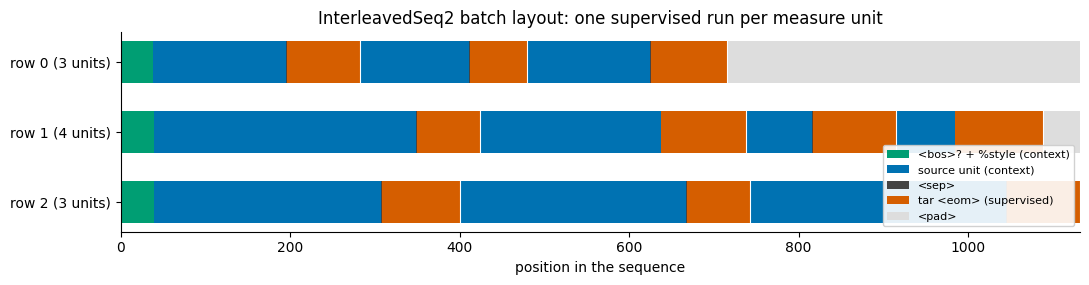

In [4]:
# Each row drawn to scale. Every orange run carries a loss; everything else is context.
fig, ax = plt.subplots(figsize=(11, 1.3 + 0.55 * len(ids)))
for r, c in enumerate(cases_b):
    first = r == 0
    pre = c['units'][0][0]
    ax.barh(r, pre, color=C_STY, height=0.6, label='<bos>? + %style (context)' if first else None)
    for u, (a, s, e) in enumerate(c['units']):
        lab = first and u == 0
        ax.barh(r, s - a, left=a, color=C_SRC, height=0.6, label='source unit (context)' if lab else None)
        ax.barh(r, 1, left=s, color='#444444', height=0.6, label='<sep>' if lab else None)
        ax.barh(r, e - s - 1, left=s + 1, color=C_TGT, height=0.6, label='tar <eom> (supervised)' if lab else None)
        ax.plot([e, e], [r - 0.3, r + 0.3], color='white', lw=0.8)
    n = len(c['ids'])
    ax.barh(r, ids.shape[1] - n, left=n, color='#dddddd', height=0.6, label='<pad>' if first else None)
ax.set_yticks(range(len(ids)))
ax.set_yticklabels(['row %d (%d units)' % (r, len(c['units'])) for r, c in enumerate(cases_b)])
ax.set_xlabel('position in the sequence')
ax.set_title('InterleavedSeq2 batch layout: one supervised run per measure unit')
ax.invert_yaxis()
ax.legend(loc='lower right', fontsize=8, framealpha=0.9)
for side in ('top', 'right'):
    ax.spines[side].set_visible(False)
plt.tight_layout(); plt.show()

### 2a. Every unit decodes back to its own measures; repeats are unrolled

Block purity cannot catch a unit paired with the WRONG measure, or a Lilylet remap that is off by the 8
dropped local controls. So each unit is rebuilt from the files: its source must equal the encoding of
MIDI played measure `played[i]` with directives dropped, and its target must decode, character for
character, to Lilylet measure `source_measures[i]`. A head crop's first MIDI unit must also carry the
file header (`ticks_per_beat`, `format_type`).

Then the corpus is scanned for crops that cross a repeat jump, where `source_measures` steps backwards.
Those are the crops on which "played order" is visible: the same Lilylet bar is a target twice.

In [5]:
def rebuild(ds, c):
    _, lyl = ds._mixed_lilylet_document(c['name'])
    midi = ds._mixed_midi(c['name'])
    out = []
    for played, measure in zip(c['played'], c['source_measures']):
        m = ds._mixed_encode_midi(ds._mixed_midi_text(midi, [played]), False)
        out.append((m, lyl[measure - 1]))
    return out

for r, c in enumerate(cases_b):
    for (a, s, e), (midi_ids, lyl_text) in zip(c['units'], rebuild(val, c)):
        src, tgt = c['ids'][a:s], c['ids'][s + 1:e - 1]
        lyl_ids, midi_side = (tgt, src) if val.target_format == 'lilylet' else (src, tgt)
        assert midi_side == midi_ids, f'row {r}: a MIDI unit is not its played measure'
        assert decode(lyl_ids) == lyl_text, f'row {r}: a Lilylet unit does not decode to its measure'
    if c['head']:
        hdr = val._mixed_encode_midi(['ticks_per_beat'], False)[:1]
        first_midi = c['ids'][c['units'][0][0]:c['units'][0][1]] if val.source_format == 'midiseq2' \
            else c['ids'][c['units'][0][1] + 1:c['units'][0][2] - 1]
        assert first_midi[:1] == hdr, 'head crop: first MIDI unit lacks the file header'
print('every unit of every row rebuilt from the files: OK')
c = cases_b[0]
a, s, e = c['units'][0]
print('\nrow 0, unit 0 (played %d -> Lilylet measure %d):' % (c['played'][0], c['source_measures'][0]))
print('  source :', decode(c['ids'][a:s])[:160].replace('\n', '\\n'), '...' if s - a > 40 else '')
print('  target :', repr(decode(c['ids'][s + 1:e - 1])))

# Repeat-crossing crops on the train arm (random crops, several passes).
repeat_files = sum(any(b <= x for x, b in zip(m, m[1:])) for m in train._measure_maps.values())
crossing = []
for _ in range(5):
    for i in train.indices:
        c = train.describe(i)
        sm = c['source_measures']
        if any(b <= x for x, b in zip(sm, sm[1:])):
            crossing.append(c)
print('\nfiles with repeats (played order steps back): %d/%d' % (repeat_files, len(train._measure_maps)))
print('train crops crossing a repeat jump: %d/%d' % (len(crossing), 5 * len(train.indices)))
if crossing:
    c = crossing[0]
    print('example %s: played %s\n         Lilylet measures %s' % (c['name'], c['played'], c['source_measures']))
    for (a, s, e), (midi_ids, lyl_text) in zip(c['units'], rebuild(train, c)):
        assert decode(c['ids'][s + 1:e - 1] if train.target_format == 'lilylet' else c['ids'][a:s]) == lyl_text
    print('  every unit of it decodes to its own (repeated) Lilylet measure: OK')

every unit of every row rebuilt from the files: OK

row 0, unit 0 (played 1 -> Lilylet measure 1):
  source : ticks_per_beat1e0format_type1time_signature2_4_18_8key_signature2_0set_tempo9bd5acontrol_change#79control_change#64control_change#65control_change#06$0ccontrol_ ...
  target : '\\staff "1" \\key d \\major \\time 2/4 \\clef "treble" \\tempo 4=94 ^\\markup "Andantino" \\p R2 \\\\\n\\staff "2" \\clef "bass" b,16\\sustainOn( fs\' fs\' fs, b, fs\' fs\' fs, |\n'



files with repeats (played order steps back): 27/99
train crops crossing a repeat jump: 6/450
example 000112b6b835b22c85719200bed7c74f: played [34, 35, 36, 37, 38, 39, 40, 41, 42]
         Lilylet measures [34, 35, 36, 37, 38, 39, 40, 41, 20]
  every unit of it decodes to its own (repeated) Lilylet measure: OK


### 2b. Style dropout: rate, and what it does to the crop

On the train arm each `%` line is dropped independently with probability `style_dropout`, so the kept
count per sample should follow Binomial(3, 0.7). The style draw has its own rng stream, so the crop
DRAW never moves with it. But here the crop is not fully independent of the style: the style block
counts toward `max_tokens`, and a crop that overshoots is trimmed by whole units. A longer style can
therefore cost a unit. That coupling is measured below rather than asserted away: across val, with
dropout 0 vs 1, the drawn range must be the same, and any difference in `played` must be explained by
`trimmed`.

train draws: 1800 (90 files x 20)
lines kept    observed  expected
0               0.0261    0.0270
1               0.1883    0.1890
2               0.4372    0.4410
3               0.3483    0.3430


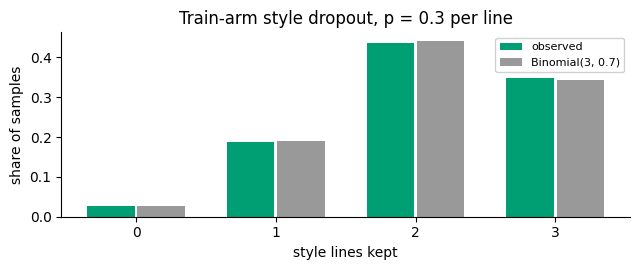


val, style dropout 0 vs 1: identical units 9 | differ by trimming 0 | unexplained 0  <- must be 0


In [6]:
from math import comb

p_drop = train.style_dropout
REPS = 20
kept_counts = []
for _ in range(REPS):
    for i in train.indices:
        style_lines, _ = train._mixed_lilylet_document(train.names[i])
        assert len(style_lines) == 3
        kept_counts.append(decode(train._pick_style(i, style_lines)).count('%'))
kept_counts = np.array(kept_counts)
observed = np.bincount(kept_counts, minlength=4) / len(kept_counts)
expected = np.array([comb(3, k) * (1 - p_drop) ** k * p_drop ** (3 - k) for k in range(4)])
print('train draws: %d (%d files x %d)' % (len(kept_counts), len(train.indices), REPS))
print('%-12s %9s %9s' % ('lines kept', 'observed', 'expected'))
for k in range(4):
    print('%-12d %9.4f %9.4f' % (k, observed[k], expected[k]))
assert abs(observed[0] - expected[0]) < 0.02 and abs(observed[3] - expected[3]) < 0.05

fig, ax = plt.subplots(figsize=(6.5, 2.8))
xk = np.arange(4)
ax.bar(xk - 0.18, observed, width=0.34, color=C_STY, label='observed')
ax.bar(xk + 0.18, expected, width=0.34, color='#999999', label='Binomial(3, %.1f)' % (1 - p_drop))
ax.set_xticks(xk); ax.set_xlabel('style lines kept'); ax.set_ylabel('share of samples')
ax.set_title('Train-arm style dropout, p = %.1f per line' % p_drop)
ax.legend(fontsize=8, framealpha=0.9)
for side in ('top', 'right'):
    ax.spines[side].set_visible(False)
plt.tight_layout(); plt.show()

DATA_ROOT = str(Path(DATA_DIR) / config['data.root'])
def val_arm(**over):
    args = dict(config['data.args']); args.update(over)
    return InterleavedSeq2.load(DATA_ROOT, args, splits=config['data.splits'],
                                args_variant={1: {**config['data.args_variant'][1], **over}})[1]

full, bare = val_arm(style_dropout=0.0), val_arm(style_dropout=1.0)
same, by_trim, unexplained = 0, 0, 0
for i in full.indices:
    a, b = full.describe(i), bare.describe(i)
    assert a['mode'] == b['mode']
    if a['played'] == b['played']:
        same += 1
        assert a['ids'][a['units'][0][0]:] == b['ids'][b['units'][0][0]:], 'same units, different ids'
    elif a['trimmed'] != b['trimmed']:
        by_trim += 1
    else:
        unexplained += 1
print('\nval, style dropout 0 vs 1: identical units %d | differ by trimming %d | unexplained %d  <- must be 0'
      % (same, by_trim, unexplained))
assert unexplained == 0

### 2c. Crop modes, unit trimming, and refused options

Over many train draws: the realized `head` / `tail` / `middle` mix against `p_head` / `p_tail` (mixed
mode has no tail degradation, so it should match), how often `max_tokens` forces a trim and how many
units it costs, and the length bound (`<= max_tokens` unless a single unit is already longer). A head
crop starts at played measure 1, a tail crop ends at the last one (trimming takes the FRONT of a tail
crop so its ending survives).

Then every Seq2Seq2 option that has no interleaved meaning must raise rather than be silently dropped.

crops drawn: 540
  head   observed 0.157  expected 0.150
  tail   observed 0.137  expected 0.150
  middle observed 0.706  expected 0.700
trimmed crops: 275/540 (50.9%), units dropped: median 4, max 11
sequence length: median 1693, max 2044 | supervised share 0.320


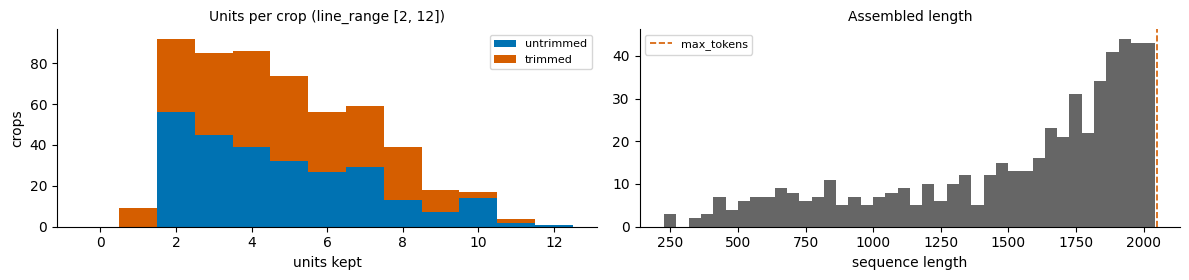


  refused  {'pos_style': 'sep'}
  refused  {'pos_style': 'absolute'}
  refused  {'pack': 'split'}
  refused  {'start_jitter': 1}
  refused  {'transposition_sigma': 1}
  refused  {'mark_mode': 'tick'}
  refused  {'packed': True}
  refused  {'source_format': 'midiseq2', 'target_format': 'midiseq2'}


In [7]:
from collections import Counter
DRAWS = 6
stats = []
for _ in range(DRAWS):
    for i in train.indices:
        c = train.describe(i)
        n_measures = len(train._measure_maps[c['name']])
        if c['mode'] == 'head':
            assert c['played'][0] == 1 and c['head']
        if c['mode'] == 'tail':
            assert c['played'][-1] == n_measures and c['tail']
        assert len(c['ids']) <= T_max or len(c['units']) == 1
        stats.append((c['mode'], len(c['units']), c['trimmed'], len(c['ids']), sum(c['target_mask'])))
modes = Counter(s[0] for s in stats)
n = len(stats)
print('crops drawn: %d' % n)
for m, p in (('head', train.p_head), ('tail', train.p_tail), ('middle', 1 - train.p_head - train.p_tail)):
    print('  %-6s observed %.3f  expected %.3f' % (m, modes[m] / n, p))
trim = np.array([s[2] for s in stats]); units = np.array([s[1] for s in stats])
lens = np.array([s[3] for s in stats]); sup = np.array([s[4] for s in stats])
print('trimmed crops: %d/%d (%.1f%%), units dropped: median %d, max %d' % (
    (trim > 0).sum(), n, 100 * (trim > 0).mean(), np.median(trim[trim > 0]) if (trim > 0).any() else 0, trim.max()))
print('sequence length: median %d, max %d | supervised share %.3f' % (np.median(lens), lens.max(), sup.sum() / lens.sum()))

fig, axes = plt.subplots(1, 2, figsize=(12, 2.9))
bins = np.arange(0, units.max() + 2) - 0.5
axes[0].hist([units[trim == 0], units[trim > 0]], bins=bins, stacked=True, color=[C_SRC, C_TGT],
             label=['untrimmed', 'trimmed'])
axes[0].set_xlabel('units kept'); axes[0].set_ylabel('crops'); axes[0].legend(fontsize=8)
axes[0].set_title('Units per crop (line_range %s)' % (list(train.line_range),), fontsize=10)
axes[1].hist(lens, bins=40, color='#666666')
axes[1].axvline(T_max, color=C_TGT, ls='--', lw=1.2, label='max_tokens')
axes[1].set_xlabel('sequence length'); axes[1].legend(fontsize=8)
axes[1].set_title('Assembled length', fontsize=10)
for ax in axes:
    for side in ('top', 'right'):
        ax.spines[side].set_visible(False)
plt.tight_layout(); plt.show()

refused = []
for bad in (dict(pos_style='sep'), dict(pos_style='absolute'), dict(pack='split'), dict(start_jitter=1),
            dict(transposition_sigma=1), dict(mark_mode='tick'), dict(packed=True),
            dict(source_format='midiseq2', target_format='midiseq2')):
    try:
        val_arm(**bad)
        refused.append((bad, False))
    except ValueError:
        refused.append((bad, True))
print()
for bad, ok in refused:
    print(('  refused  ' if ok else '  ACCEPTED ') + str(bad))
assert all(ok for _, ok in refused)

### 2d. Bar-boundary jitter: the source cut moves, the target does not

At inference the bar lines come from stage 1 (`tools/midi/translateMidiseq2ToLilylet.py`): a regular
model's `<eom>` written back onto the source, which lands off the true bar line by whole source lines.
Training otherwise cuts every unit exactly at `@measure`, so the train arm moves each bar line the crop
touches by `round(gauss(boundary_jitter_mean, boundary_jitter_std))` content lines (+ = later: the bar
before it ends with the next bar's first lines). The val arm turns it off and measures the exact cut.

Checked here, on the train arm's own draws:
- the applied shifts follow the configured distribution, apart from the order clamp;
- **conservation**: the units' sources concatenate to exactly the content between the crop's outer cuts,
  so no line is lost or duplicated, and the file's first and last line never move;
- **the crop and the targets are untouched**: a jittered arm and an exact one, on the same deterministic
  draw, agree on the played range and on every target bar, and differ only in the sources.

train arm: boundary_jitter mean +4 std 6 | val arm: mean +0 std 0


movable edges 4032 | applied shift mean +3.91 std 5.98 (configured +4 / 6) | clamped 46 (1.14%) | empty source units 40/3548


val crops, jitter on vs off: identical crops and targets on all 9; 43/44 source units changed


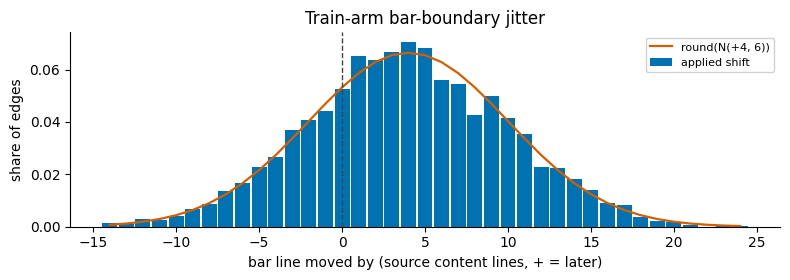

In [8]:
mu, sd = train.boundary_jitter_mean, train.boundary_jitter_std
print('train arm: boundary_jitter mean %+g std %g | val arm: mean %+g std %g' % (
    mu, sd, val.boundary_jitter_mean, val.boundary_jitter_std))
assert (val.boundary_jitter_mean, val.boundary_jitter_std) == (0, 0), 'val must measure the exact cut'

shifts, clamped, edges, empty, n_units = [], 0, 0, 0, 0
for _ in range(8):
    for i in train.indices:
        c = train.describe(i)
        content, starts = train._bar_content(train._mixed_midi(c['name']))
        cuts = c['source_cuts']
        srcs = [c['ids'][a:s] for a, s, _ in c['units']]
        assert sum(srcs, []) == train._mixed_encode_midi(content[cuts[0]:cuts[-1]], False), 'a line was lost or duplicated'
        assert c['a'] or cuts[0] == 0
        assert c['z'] < len(starts) - 1 or cuts[-1] == starts[-1]
        s = [x for x in c['boundary_shift'] if x is not None]
        shifts += s; edges += len(s); clamped += c['boundary_clamped']
        n_units += len(c['units']); empty += sum(a == s_ for a, s_, _ in c['units'])
shifts = np.array(shifts)
print('movable edges %d | applied shift mean %+.2f std %.2f (configured %+g / %g) | clamped %d (%.2f%%) | empty source units %d/%d'
      % (edges, shifts.mean(), shifts.std(), mu, sd, clamped, 100 * clamped / max(1, edges), empty, n_units))
assert abs(shifts.mean() - mu) < 0.5 and abs(shifts.std() - sd) < 0.5

# Same deterministic draw, jitter on vs off: the crop and every target bar agree, only the sources move.
exact, jittered = val_arm(boundary_jitter_mean=0, boundary_jitter_std=0), val_arm(boundary_jitter_mean=mu, boundary_jitter_std=sd)
moved_units = total_units = 0
for i in exact.indices:
    a, b = exact.describe(i), jittered.describe(i)
    assert a['played'] == b['played'], 'jitter moved the crop'
    assert [a['ids'][s + 1:e] for _, s, e in a['units']] == [b['ids'][s + 1:e] for _, s, e in b['units']], 'a target moved'
    moved_units += sum(a['ids'][x:s] != b['ids'][y:t] for (x, s, _), (y, t, _) in zip(a['units'], b['units']))
    total_units += len(a['units'])
print('val crops, jitter on vs off: identical crops and targets on all %d; %d/%d source units changed' % (
    len(exact.indices), moved_units, total_units))

fig, ax = plt.subplots(figsize=(8, 2.9))
lo, hi = int(shifts.min()), int(shifts.max())
xs = np.arange(lo, hi + 1)
ax.bar(xs, np.bincount(shifts - lo, minlength=len(xs)) / len(shifts), width=0.9, color=C_SRC, label='applied shift')
from math import erf, sqrt
cdf = lambda x: 0.5 * (1 + erf((x - mu) / (sd * sqrt(2))))
ax.plot(xs, [cdf(x + 0.5) - cdf(x - 0.5) for x in xs], color=C_TGT, lw=1.6, label='round(N(%+g, %g))' % (mu, sd))
ax.axvline(0, color='#444444', lw=1, ls='--')
ax.set_xlabel('bar line moved by (source content lines, + = later)'); ax.set_ylabel('share of edges')
ax.set_title('Train-arm bar-boundary jitter')
ax.legend(fontsize=8, framealpha=0.9)
for side in ('top', 'right'):
    ax.spines[side].set_visible(False)
plt.tight_layout(); plt.show()

In [9]:
# One shifted bar line, shown as text: the lines on either side of a cut, exact vs jittered.
for i in exact.indices:
    a, b = exact.describe(i), jittered.describe(i)
    k = next((k for k, x in enumerate(b['boundary_shift'][1:-1], 1) if x and abs(x) >= 3), None)
    if k is not None:
        break
content, _ = exact._bar_content(exact._mixed_midi(a['name']))
ca, cb = a['source_cuts'][k], b['source_cuts'][k]
print('%s, bar line before played bar %d moved %+d lines (exact cut at content line %d, jittered at %d):\n' % (
    a['name'][:10], a['played'][k], cb - ca, ca, cb))
for j in range(min(ca, cb) - 3, max(ca, cb) + 3):
    mark = ('E' if j == ca else ' ') + ('J' if j == cb else ' ')
    print('  %s %5d  %s' % (mark, j, content[j]))
print('\n  E = exact bar line, J = jittered: the lines between them changed bars')

0000d32362, bar line before played bar 2 moved -7 lines (exact cut at content line 66, jittered at 59):

        56  E010
        57  note_on #42 $31
        58  E040 E2
   J    59  control_change #02 $31
        60  E030 E5
        61  note_on #36 $30
        62  E6
        63  note_off #42
        64  E030 Ed
        65  control_change #02 $31
  E     66  E030 E4
        67  note_on #2f $32
        68  E5

  E = exact bar line, J = jittered: the lines between them changed bars


## 3. The shift, on a hand-built two-unit row

The probe row is

`[<bos>, %, x, \n, \n, m1, m2, <sep>, l1, l2, <eom>, m1, <sep>, l1, <eom>, <pad>]`

with `target_mask` on positions 8-10 and 13-14. Synthetic logits make the argmax at position `t` equal
to `t * 50`, so the logits row behind each label can be read off. What has to come out:
- labels `[l1, l2, <eom>, l1, <eom>]`: no style id, no source id, no `<sep>`;
- logits rows `[7, 8, 9, 12, 13]`: each unit's first label is predicted from its own `<sep>` (7 and 12),
  and the second unit's source `m1` at 11 — right after an `<eom>` — is not a label.

In [10]:
SEP, EOM, PAD, BOS = tok.sep_id, tok.eom_id, tok.pad_id, tok.bos_id
L = tok.lilylet_id_by_token
M = tok.midiseq2_id_by_token
m1, m2 = M['note_on'], M['#3c']
pct, xch, nl, l1, l2 = L['%'], L['x'], L['\n'], L['c'], L['4']
probe_ids = [BOS, pct, xch, nl, nl, m1, m2, SEP, l1, l2, EOM, m1, SEP, l1, EOM, PAD]
sup = [8, 9, 10, 13, 14]
T = len(probe_ids)
probe = dict(
    input_ids=torch.tensor([probe_ids]),
    masks=torch.tensor([[1] * (T - 1) + [0]]),
    target_mask=torch.tensor([[1 if t in sup else 0 for t in range(T)]]),
)
fake = torch.full((1, T, model.deducer.vocab_size), -10.0)
for t in range(T):
    fake[0, t, t * 50] = 10.0          # argmax at position t is t * 50 (< 838 for t <= 15)

pred, labels = model._shift(probe, fake)
used_rows = (pred.argmax(dim=-1) // 50).tolist()
print('labels    :', [tok.tokens[i] for i in labels.tolist()])
print('logits row:', used_rows, '  (expect [7, 8, 9, 12, 13])')
roles = ['<bos>', 'style', 'style', 'style', 'blank line', 'src 1', 'src 1', '<sep>', 'TAR 1', 'TAR 1', 'TAR 1 <eom>',
         'src 2', '<sep>', 'TAR 2', 'TAR 2 <eom>', 'padding']
print()
print('%-4s %-10s %-13s %s' % ('pos', 'input', 'role', 'predicted from'))
for t in range(T):
    print('%-4d %-10r %-13s %s' % (t, tok.tokens[probe_ids[t]], roles[t], ('pos %d' % (t - 1)) if t in sup else '-'))
assert labels.tolist() == [l1, l2, EOM, l1, EOM]
assert used_rows == [7, 8, 9, 12, 13], used_rows
print('\nshift geometry over two units OK')

labels    : ['c', '4', '<eom>', 'c', '<eom>']
logits row: [7, 8, 9, 12, 13]   (expect [7, 8, 9, 12, 13])

pos  input      role          predicted from
0    '<bos>'    <bos>         -
1    '%'        style         -
2    'x'        style         -
3    '\n'       style         -
4    '\n'       blank line    -
5    'note_on'  src 1         -
6    '#3c'      src 1         -
7    '<sep>'    <sep>         -
8    'c'        TAR 1         pos 7
9    '4'        TAR 1         pos 8
10   '<eom>'    TAR 1 <eom>   pos 9
11   'note_on'  src 2         -
12   '<sep>'    <sep>         -
13   'c'        TAR 2         pos 12
14   '<eom>'    TAR 2 <eom>   pos 13
15   '<pad>'    padding       -

shift geometry over two units OK


In [11]:
# The same on the REAL batch, verified positionally, plus: every unit's first label is predicted from
# its own <sep>, and the position right after each <eom> (next unit's source) is never a label.
with torch.no_grad():
    logits = model.deducer(ids, masks, posn)
pred_r, labels_r = model._shift(batch, logits)

expect_labels, expect_logits = [], []
for r in range(len(ids)):
    for t in range(ids.shape[1]):
        if tmask[r, t] == 1:
            expect_labels.append(int(ids[r, t])); expect_logits.append(logits[r, t - 1])
from_sep = all(int(ids[r, s]) == SEP and tmask[r, s] == 0 and tmask[r, s + 1] == 1
               for r, c in enumerate(cases_b) for _, s, _ in c['units'])
after_eom = [int(tmask[r, e]) for r, c in enumerate(cases_b) for _, _, e in c['units'][:-1]]
print('supervised positions      :', len(expect_labels), '| _shift returned:', int(labels_r.numel()))
print('labels match position-wise:', labels_r.tolist() == expect_labels)
print('logits match position-wise:', torch.allclose(pred_r, torch.stack(expect_logits)))
print('each unit\'s first label is predicted from its <sep>:', from_sep)
print('labels right after a non-final <eom>:', sum(after_eom), '/', len(after_eom), '  <- must be 0')
assert labels_r.tolist() == expect_labels
assert torch.allclose(pred_r, torch.stack(expect_logits))
assert from_sep and sum(after_eom) == 0

supervised positions      : 871 | _shift returned: 871
labels match position-wise: True
logits match position-wise: True
each unit's first label is predicted from its <sep>: True
labels right after a non-final <eom>: 0 / 7   <- must be 0


## 4. Causality and conditioning: own source, history, style

Teacher forcing is honest only if the stack is causal, which is checked, not assumed. Beyond that, a
target bar `u` has three channels it must be able to read, and the loss enforces none of them directly:

- **Own source.** Perturbing unit `u`'s source must move unit `u`'s target logits — and must NOT move
  any earlier unit's target (those were generated before that bar was shown).
- **History.** Perturbing an EARLIER unit's target must move unit `u`'s target. This is what lets the
  model keep voices, key and spelling consistent bar to bar; it is the reason to interleave at all.
- **Style.** The unsupervised prefix must reach unit `u`'s target, or `style_dropout` augments nothing.

Perturbations stay inside the token's own vocabulary block, so the row remains well-formed.

perturb own source (unit 2)        at  777 ('E5'    ) -> unit 2 target moves 7.669e-04 | anything before it moves 0.0e+00
perturb history target (unit 1)    at  688 ("'"     ) -> unit 2 target moves 9.405e-04 | anything before it moves 0.0e+00
perturb style                      at   19 ('C'     ) -> unit 2 target moves 3.694e-03 | anything before it moves 0.0e+00

unit 2 source perturbed -> earlier targets move 0.0e+00  <- must be 0


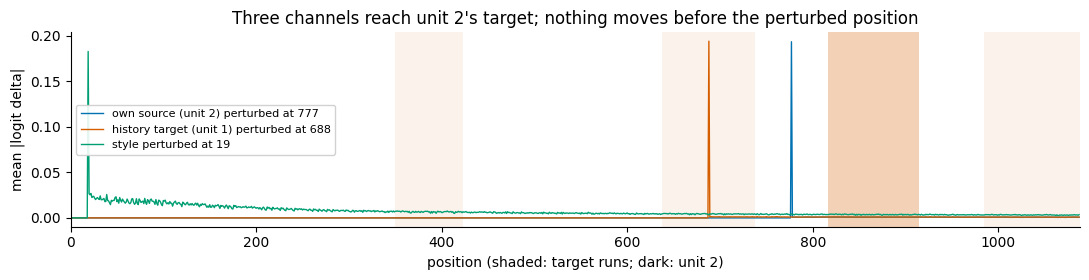

In [12]:
model.eval()
R = max(range(len(cases_b)), key=lambda r: len(cases_b[r]['units']))
c = cases_b[R]
assert len(c['units']) >= 3, 'need a row with at least 3 units'
n0 = len(c['ids'])
row, row_mask, row_pos = ids[R:R + 1, :n0].clone(), masks[R:R + 1, :n0], posn[R:R + 1, :n0]
U = len(c['units']) // 2
ua, us, ue = c['units'][U]
pa, ps, pe = c['units'][U - 1]

def same_block_swap(i, off=37):
    i = int(i)
    lo, size = (MID0, MIDN) if is_mid(i) else (LYL0, LYLN) if is_lyl(i) else (0, 16)
    return lo + (i - lo + off) % size

def run(x):
    with torch.no_grad():
        return model.deducer(x, row_mask, row_pos)[0]

def perturb(pos):
    x = row.clone(); x[0, pos] = same_block_swap(row[0, pos]); return x

base = run(row)
tgt_u = slice(us + 1, ue)
probes = {
    'own source (unit %d)' % U: (ua + (us - ua) // 2, C_SRC),
    'history target (unit %d)' % (U - 1): (ps + 1 + (pe - ps - 1) // 2, C_TGT),
    'style': (int(c['head']) + c['style'] // 2, C_STY),
}
deltas = {}
for name, (pos, _) in probes.items():
    d = (run(perturb(pos)) - base).abs().mean(dim=-1)
    deltas[name] = d
    print('perturb %-26s at %4d (%-8r) -> unit %d target moves %.3e | anything before it moves %.1e'
          % (name, pos, tok.tokens[int(row[0, pos])], U, d[tgt_u].mean(), d[:pos].max() if pos else 0))
    assert d[tgt_u].mean() > 0, f'unit {U} target cannot see {name}'
    assert pos == 0 or d[:pos].max() == 0, 'future leak'

own = deltas['own source (unit %d)' % U]
earlier_tgts = torch.cat([own[s + 1:e] for _, s, e in c['units'][:U]])
print('\nunit %d source perturbed -> earlier targets move %.1e  <- must be 0' % (U, earlier_tgts.max()))
assert earlier_tgts.max() == 0

fig, ax = plt.subplots(figsize=(11, 2.9))
for name, (pos, color) in probes.items():
    ax.plot(deltas[name].numpy(), color=color, lw=1.0, label=f'{name} perturbed at {pos}')
for a, s, e in c['units']:
    ax.axvspan(s + 0.5, e - 0.5, color=C_TGT, alpha=0.08, lw=0)
ax.axvspan(us + 0.5, ue - 0.5, color=C_TGT, alpha=0.22, lw=0)
ax.set_xlim(0, n0)
ax.set_xlabel('position (shaded: target runs; dark: unit %d)' % U); ax.set_ylabel('mean |logit delta|')
ax.set_title('Three channels reach unit %d\'s target; nothing moves before the perturbed position' % U)
ax.legend(fontsize=8, framealpha=0.9)
for side in ('top', 'right'):
    ax.spines[side].set_visible(False)
plt.tight_layout(); plt.show()

### 4a. The visibility matrix, measured rather than drawn

For every key position `j`, perturb it and record which query positions move. The result is the
attention mask the stack actually applies. The demo row is short but built from a real sample: the
style block's closing `\n\n`, then two units, each `src (≤5) <sep> tar (≤4) <eom>`, then 4 pads. It must
be exactly lower-triangular over the real positions, no pad column may reach a real query, and unit 2's
target queries must see every key of unit 1 — source and target.

empirical == hand-drawn causal mask: True
future leaks                       : 0   <- must be 0
pad columns reaching a real query  : 0   <- must be 0
unit-2 target sees all of unit 1   : True


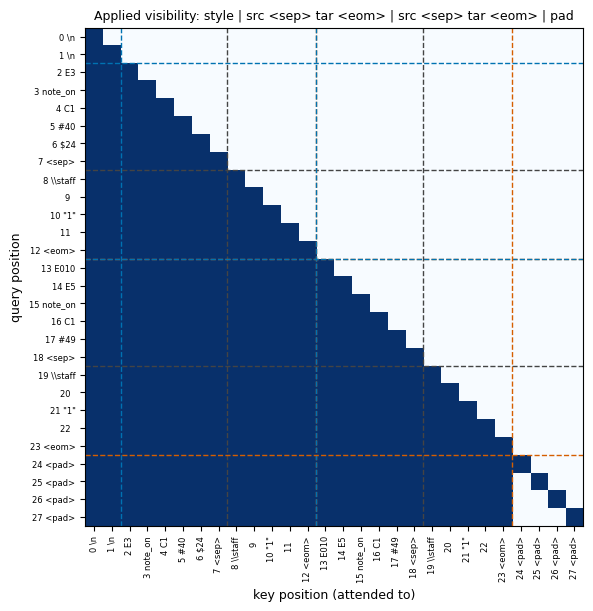

In [13]:
c = cases_b[R]
full_row = c['ids']
p0 = c['units'][0][0]
parts = [full_row[p0 - 2:p0]] if c['style'] else []
bounds = []
for a, s, e in c['units'][:2]:
    src, tgt = full_row[a:s][:5], full_row[s + 1:e - 1][:4]
    start = sum(len(p) for p in parts)
    parts.append(src + [SEP] + tgt + [EOM])
    bounds.append((start, start + len(src), start + len(src) + len(tgt) + 2))
n_real = sum(len(p) for p in parts)
S_PAD = 4
demo_ids = torch.tensor([sum(parts, []) + [PAD] * S_PAD])
T_d = demo_ids.shape[1]
demo_mask = torch.zeros(1, T_d, dtype=torch.long); demo_mask[0, :n_real] = 1

with torch.no_grad():
    base_d = model.deducer(demo_ids, demo_mask)[0]
vis = np.zeros((T_d, T_d))
for j in range(T_d):
    moved = torch.zeros(T_d)
    for off in (37, 211):
        b_ = demo_ids.clone(); b_[0, j] = (int(demo_ids[0, j]) + off) % model.deducer.vocab_size
        with torch.no_grad():
            moved = torch.maximum(moved, (model.deducer(b_, demo_mask)[0] - base_d).abs().mean(dim=-1))
    vis[:, j] = (moved > 1e-7).numpy()

qi, kj = np.arange(T_d)[:, None], np.arange(T_d)[None, :]
real = demo_mask[0].numpy() == 1
theory = ((kj <= qi) & real[None, :] & real[:, None]).astype(float)
(u1a, u1s, u1e), (u2a, u2s, u2e) = bounds
print('empirical == hand-drawn causal mask:', np.array_equal(vis[:n_real, :n_real], theory[:n_real, :n_real]))
print('future leaks                       :', int(vis[np.triu_indices(n_real, 1)].sum()), '  <- must be 0')
print('pad columns reaching a real query  :', int(vis[:n_real, n_real:].sum()), '  <- must be 0')
print('unit-2 target sees all of unit 1   :', bool(vis[u2s + 1:u2e, u1a:u1e].all()))
assert np.array_equal(vis[:n_real, :n_real], theory[:n_real, :n_real])
assert vis[:n_real, n_real:].sum() == 0 and vis[u2s + 1:u2e, u1a:u1e].all()

fig, ax = plt.subplots(figsize=(6.4, 6.0), layout='constrained')
ax.imshow(vis, cmap='Blues', vmin=0, vmax=1, interpolation='nearest')
lab = ['%d %s' % (i, repr(tok.tokens[int(t)])[1:-1][:8]) for i, t in enumerate(demo_ids[0])]
ax.set_xticks(range(T_d)); ax.set_yticks(range(T_d))
ax.set_xticklabels(lab, rotation=90, fontsize=6); ax.set_yticklabels(lab, fontsize=6)
for a, s, e in bounds:
    for v, color in ((a - 0.5, C_SRC), (s + 0.5, '#444444'), (e - 0.5, C_TGT)):
        ax.axvline(v, color=color, lw=1.0, ls='--'); ax.axhline(v, color=color, lw=1.0, ls='--')
ax.set_xlabel('key position (attended to)', fontsize=9); ax.set_ylabel('query position', fontsize=9)
ax.set_title('Applied visibility: style | src <sep> tar <eom> | src <sep> tar <eom> | pad', fontsize=9)
plt.show()

## 5. Padding invariance

Right-padding must not change the loss, and the batch loss must be the token-weighted mean of the
per-row losses, with weights equal to each row's SUPERVISED count (all its `tar <eom>` runs).

In [14]:
def pad_to(b, extra):
    z = lambda t: torch.cat([t, torch.zeros(t.shape[0], extra, dtype=t.dtype)], dim=1)
    grow = torch.stack([p[-1] + torch.arange(1, extra + 1) for p in b['position_ids']])
    return dict(input_ids=z(b['input_ids']), masks=z(b['masks']), target_mask=z(b['target_mask']),
                position_ids=torch.cat([b['position_ids'], grow], dim=1))

model.eval()
with torch.no_grad():
    l_plain, _ = model(batch)
    l_padded, _ = model(pad_to(batch, 64))
    per_row = [model({k: v[r:r + 1, :int(masks[r].sum())] for k, v in batch.items()})[0].item()
               for r in range(len(ids))]
print('loss, batch           : %.8f' % l_plain.item())
print('loss, + 64 pad columns: %.8f   delta %.2e' % (l_padded.item(), abs(l_plain.item() - l_padded.item())))
assert abs(l_plain.item() - l_padded.item()) < 1e-5

w = tmask.sum(dim=1).float()
weighted = float((torch.tensor(per_row) * w).sum() / w.sum())
print('\nper-row losses (unpadded):', ['%.4f' % x for x in per_row])
print('supervised counts       :', w.long().tolist())
print('token-weighted mean     : %.8f   (batch loss %.8f)' % (weighted, l_plain.item()))
assert abs(weighted - l_plain.item()) < 1e-4

loss, batch           : 6.75620651
loss, + 64 pad columns: 6.75620651   delta 0.00e+00

per-row losses (unpadded): ['6.7707', '6.7653', '6.7286']
supervised counts       : [244, 375, 252]
token-weighted mean     : 6.75620604   (batch loss 6.75620651)


## 6. Loss, metrics, and the `<eom>` blind spot

The unified branch of `MidiTranslatorLoss` has one class per vocabulary region: shared controls are
`special`, `<sep>` is `sep`, the midiseq2 block keeps its fine partition, and the whole Lilylet block is
`lyl`. With a Lilylet target the eval error panel is `error/lyl` alone (a midiseq2 target would show
the midiseq2 classes instead).

The supervised `<eom>` falls under `special`, which the panel does not report. In this feeder `<eom>` is
the ONLY stop signal — there is no `<eos>` — so a model that never closes a bar would not show up in
`error/*` at all, only as a small dent in `acc`. `eom_metrics` below computes it directly, both as
recall (an `<eom>` label predicted as `<eom>`) and as precision (an `<eom>` prediction that was one).

In [15]:
model.train()
loss_tr, m_tr = model(batch)
model.eval()
with torch.no_grad():
    loss_ev, m_ev = model(batch)
print('TRAIN keys:', sorted(m_tr.keys()))
print('EVAL  keys:', sorted(m_ev.keys()))
print('\nloss %.4f vs ln(838) = %.4f  (random-init sanity)' % (loss_ev.item(), np.log(model.deducer.vocab_size)))
assert m_tr['acc'].weight == int(tmask.sum())
stat_ev = model.stat(dict(m_ev), 1)
print('stat(eval):', stat_ev)
tgt_class = 'lyl' if val.target_format == 'lilylet' else None
if tgt_class:
    assert set(stat_ev['error']) == {'lyl'}, 'a Lilylet target should report only error/lyl'

n_eom = int((labels_r == EOM).sum())
special = int((model.type_of_id[labels_r] == 0).sum())
print('\nsupervised tokens %d | <eom> labels %d (%.1f%%) | in class `special` %d  <- reported nowhere in error/*'
      % (labels_r.numel(), n_eom, 100 * n_eom / labels_r.numel(), special))
assert n_eom == special == sum(len(c['units']) for c in cases_b)

def eom_metrics(pred_logits, labels):
    p = pred_logits.argmax(dim=-1)
    hit = ((p == EOM) & (labels == EOM)).sum().item()
    return dict(recall=hit / max(1, int((labels == EOM).sum())), precision=hit / max(1, int((p == EOM).sum())),
                predicted=int((p == EOM).sum()))
print('random-init <eom>:', eom_metrics(pred_r, labels_r))

TRAIN keys: ['acc', 'err']
EVAL  keys: ['acc', 'err', 'err_channel', 'err_elapse', 'err_lyl', 'err_nibble', 'err_pitch', 'err_type', 'err_vel']

loss 6.7562 vs ln(838) = 6.7310  (random-init sanity)
stat(eval): {'acc': 0.0, 'err': 1.0, 'error': {'lyl': 1.0}}

supervised tokens 871 | <eom> labels 10 (1.1%) | in class `special` 10  <- reported nowhere in error/*
random-init <eom>: {'recall': 0.0, 'precision': 0.0, 'predicted': 0}


supervised tokens: 871

whitespace         305   35.0%
pitch letter       149   17.1%
other symbol       122   14.0%
protected word     118   13.5%
digit               94   10.8%
octave mark         60    6.9%
bar line            13    1.5%
<eom>               10    1.1%


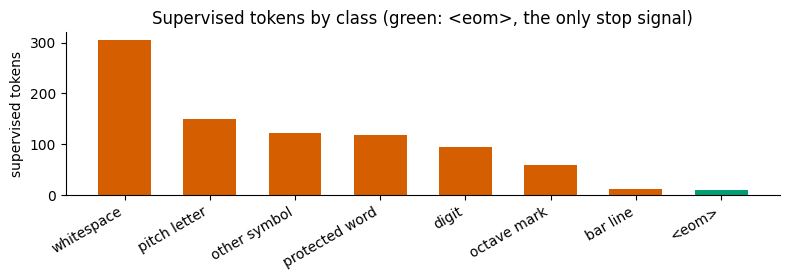

In [16]:
# Composition of the supervised region by character class (Lilylet target) — what error/lyl averages over.
lyl_types = {e['token']: e.get('type') for e in val.lilylet_tokenizer.vocab}
def char_class(i):
    t = tok.tokens[i]
    if i == EOM: return '<eom>'
    if i < 16: return 'control'
    if is_mid(i): return 'midiseq2'
    if lyl_types.get(t) == 'protected' and len(t) > 1: return 'protected word'
    if t in (' ', '\n'): return 'whitespace'
    if re.fullmatch(r'[a-g]', t): return 'pitch letter'
    if t in ("'", ','): return 'octave mark'
    if t.isdigit(): return 'digit'
    if t == '|': return 'bar line'
    if t == '\\': return 'backslash'
    return 'other symbol'

comp = Counter(char_class(int(i)) for i in labels_r)
total = sum(comp.values())
print('supervised tokens: %d\n' % total)
for name, cnt in comp.most_common():
    print('%-15s %6d %6.1f%%' % (name, cnt, 100 * cnt / total))

fig, ax = plt.subplots(figsize=(8, 2.9))
names, vals = zip(*comp.most_common())
ax.bar(range(len(names)), vals, color=[C_STY if n == '<eom>' else C_TGT for n in names], width=0.62)
ax.set_xticks(range(len(names))); ax.set_xticklabels(names, rotation=30, ha='right')
ax.set_ylabel('supervised tokens')
ax.set_title('Supervised tokens by class (green: <eom>, the only stop signal)')
for side in ('top', 'right'):
    ax.spines[side].set_visible(False)
plt.tight_layout(); plt.show()

## 7. Checkpoint contract

The trainer saves only `model.deducer.state_dict()`. The unified type map and CE weights are derived
from the pinned vocab artifact, so they must be non-persistent buffers, and the embedding must have the
artifact's 838 rows.

In [17]:
wrapper_only = [n for n, _ in model.named_parameters() if not n.startswith('deducer.')]
saved = model.deducer.state_dict()
emb = [v for k_, v in saved.items() if k_.endswith('embed_tokens.weight')][0]
print('trainable params outside deducer:', wrapper_only, '(must be empty)')
print('embedding rows                  :', emb.shape[0], '(must be %d)' % tok.vocab_size)
print('non-persistent wrapper buffers  :', [n for n in ('type_of_id', 'ce_weight_of_id') if n not in model.state_dict()])
assert not wrapper_only and emb.shape[0] == tok.vocab_size
fresh = loadModel({'type': config['model.type'], 'args': small}, postfix='Loss', imports=config['imports'])
print('state_dict round-trips:', fresh.deducer.load_state_dict(saved, strict=True))

trainable params outside deducer: [] (must be empty)
embedding rows                  : 838 (must be 838)
non-persistent wrapper buffers  : ['type_of_id', 'ce_weight_of_id']


state_dict round-trips: <All keys matched successfully>


## 8. Overfit one batch

The end-to-end gradient check: loss must fall toward 0 and accuracy approach 1 on one batch, which
says the multi-run mask, the shift and the backprop path agree. `<eom>` recall and precision are tracked
too, since the headline accuracy can reach 0.95 while every bar stays open. Nothing here is about
generalization.

step   0: loss 6.7411  acc 0.000
step 199: loss 0.0332  acc 0.991
acc crosses 0.9 at step 68 | 0.95 at step 74
<eom> after overfit: {'recall': 1.0, 'precision': 1.0, 'predicted': 10}


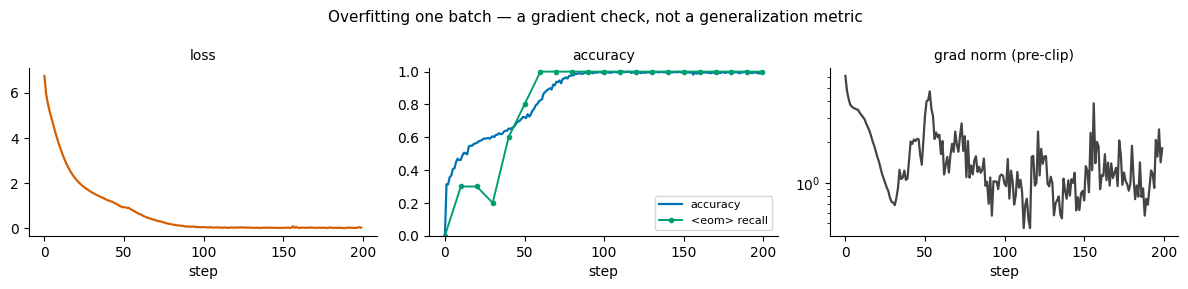

In [18]:
over = loadModel({'type': config['model.type'], 'args': small}, postfix='Loss', imports=config['imports'])
over.train()
opt = torch.optim.Adam(over.parameters(), lr=1.5e-3)
history = []
STEPS = 200
for step in range(STEPS):
    opt.zero_grad()
    loss, metric = over(batch)
    loss.backward()
    gn = torch.nn.utils.clip_grad_norm_([p for p in over.parameters() if p.requires_grad], float('inf'))
    opt.step()
    rec = None
    if step % 10 == 0 or step == STEPS - 1:
        with torch.no_grad():
            pr, lb = over._shift(batch, over._logits(batch))
        rec = eom_metrics(pr, lb)['recall']
    history.append((loss.item(), metric['acc'].value, float(gn), rec))

acc_curve = np.array([h[1] for h in history])
cross = lambda th: int(np.argmax(acc_curve >= th)) if (acc_curve >= th).any() else None
print('step   0: loss %.4f  acc %.3f' % history[0][:2])
print('step %3d: loss %.4f  acc %.3f' % ((STEPS - 1,) + history[-1][:2]))
print('acc crosses 0.9 at step', cross(0.9), '| 0.95 at step', cross(0.95))
over.eval()
with torch.no_grad():
    pr, lb = over._shift(batch, over._logits(batch))
print('<eom> after overfit:', eom_metrics(pr, lb))
assert history[-1][0] < history[0][0] * 0.05, 'loss did not fall — the gradient path is broken'
assert history[-1][1] > 0.95, 'accuracy did not reach the batch'

fig, axes = plt.subplots(1, 3, figsize=(12, 2.9))
axes[0].plot([h[0] for h in history], color=C_TGT, lw=1.6); axes[0].set_title('loss', fontsize=10)
axes[1].plot(acc_curve, color=C_SRC, lw=1.6, label='accuracy')
er = [(i, h[3]) for i, h in enumerate(history) if h[3] is not None]
axes[1].plot(*zip(*er), color=C_STY, lw=1.4, marker='o', ms=3, label='<eom> recall')
axes[1].set_ylim(0, 1.02); axes[1].legend(fontsize=8); axes[1].set_title('accuracy', fontsize=10)
axes[2].plot([h[2] for h in history], color='#444444', lw=1.6); axes[2].set_yscale('log')
axes[2].set_title('grad norm (pre-clip)', fontsize=10)
for ax in axes:
    ax.set_xlabel('step')
    for side in ('top', 'right'):
        ax.spines[side].set_visible(False)
fig.suptitle('Overfitting one batch — a gradient check, not a generalization metric', fontsize=11)
plt.tight_layout(); plt.show()

## 9. Measure-by-measure free run, teacher-forced and self-fed

Production decodes one bar at a time: append `src_k <sep>`, call `generate(..., eos_id=<eom>)`, and
the bar is done when `<eom>` comes out. Two histories are compared on the batch-overfitted model from
section 8, on the row with the most units:

- **teacher-forced**: earlier bars are the REFERENCE targets, so each bar is decoded in isolation;
- **self-fed**: earlier bars are the model's OWN output, which is what inference really does, so an
  early mistake can propagate.

Per bar: did it stop at `<eom>`, does it match the reference exactly, and how many ids from the wrong
vocabulary block did it emit (nothing masks the logits by block). The model memorized this row, so
this shows the mechanism working, not translation quality.

In [19]:
c = cases_b[R]
row_ids = c['ids']
prefix0 = row_ids[:c['units'][0][0]]
MAX_BAR = 400

def decode_bars(self_fed):
    seq = list(prefix0)
    out = []
    for a, s, e in c['units']:
        seq += row_ids[a:s] + [SEP]
        truth = row_ids[s + 1:e]
        gen = over.deducer.generate(torch.tensor(seq), max_new_tokens=min(MAX_BAR, len(truth) + 40),
                                    eos_id=EOM, temperature=0.0).tolist()
        out.append(dict(gen=gen, truth=truth, stopped=bool(gen) and gen[-1] == EOM, exact=gen == truth,
                        off_block=sum(1 for i in gen if not is_ctl(i) and not TGT_IS(i))))
        seq += gen if self_fed else truth
    return out

over.eval()
runs = {'teacher-forced': decode_bars(False), 'self-fed': decode_bars(True)}
print('sample %s | %d bars | played %s' % (c['name'], len(c['units']), c['played']))
for name, bars in runs.items():
    print('%-15s stopped at <eom> %2d/%d | exact %2d/%d | off-block ids %d | first wrong bar %s' % (
        name, sum(b['stopped'] for b in bars), len(bars), sum(b['exact'] for b in bars), len(bars),
        sum(b['off_block'] for b in bars), next((i for i, b in enumerate(bars) if not b['exact']), None)))

strip = lambda seq: decode([i for i in seq if not is_ctl(int(i))])
for i in range(min(2, len(c['units']))):
    print('\nbar %d reference : %r' % (i, strip(runs['self-fed'][i]['truth'])[:200]))
    print('bar %d self-fed  : %r' % (i, strip(runs['self-fed'][i]['gen'])[:200]))

sample 000167012355a695589c9ea5fd8e9c0b | 4 bars | played [42, 43, 44, 45]
teacher-forced  stopped at <eom>  4/4 | exact  4/4 | off-block ids 0 | first wrong bar None
self-fed        stopped at <eom>  4/4 | exact  4/4 | off-block ids 0 | first wrong bar None

bar 0 reference : '\\staff "1" \\key a \\major \\time 6/8 e\'4 r8 r4 r8 \\\\\\\n\\staff "1" <cs\' e cs\'>2.\\pp \\\\\n\\staff "2" \\clef "treble" <a e\' a>2. |\n'
bar 0 self-fed  : '\\staff "1" \\key a \\major \\time 6/8 e\'4 r8 r4 r8 \\\\\\\n\\staff "1" <cs\' e cs\'>2.\\pp \\\\\n\\staff "2" \\clef "treble" <a e\' a>2. |\n'

bar 1 reference : '\\staff "1" \\key a \\major \\time 6/8 R2. \\\\\\\n\\staff "1" <cs\' e cs\'>2. \\\\\n\\staff "2" <a e\' a>2. \\\\\n\\staff "2" <cs\' e a cs>8\\arpeggio s s <a cs e a>\\arpeggio s4 |\n'
bar 1 self-fed  : '\\staff "1" \\key a \\major \\time 6/8 R2. \\\\\\\n\\staff "1" <cs\' e cs\'>2. \\\\\n\\staff "2" <a e\' a>2. \\\\\n\\staff "2" <cs\' e a cs>8\\arpeggio s s <a cs e a>\\arpeggio s4 |\n'


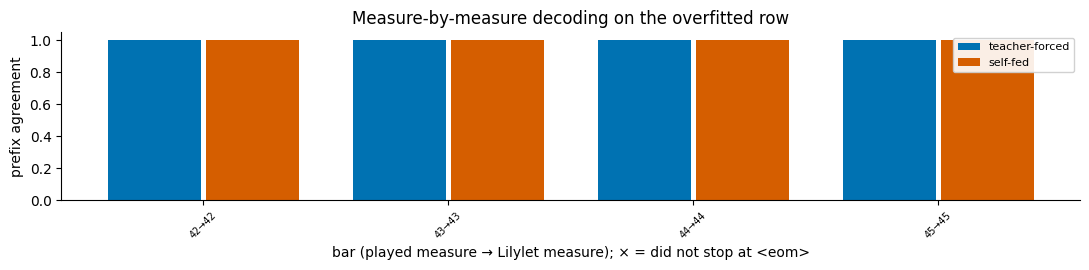

In [20]:
# Per-bar prefix agreement: the share of each reference bar reproduced before the first divergence.
def agreement(b):
    n = min(len(b['gen']), len(b['truth']))
    k = next((j for j in range(n) if b['gen'][j] != b['truth'][j]), n)
    return k / len(b['truth'])

fig, ax = plt.subplots(figsize=(11, 2.8))
xb = np.arange(len(c['units']))
for off, (name, color) in zip((-0.2, 0.2), (('teacher-forced', C_SRC), ('self-fed', C_TGT))):
    ax.bar(xb + off, [agreement(b) for b in runs[name]], width=0.38, color=color, label=name)
    for x, b in zip(xb, runs[name]):
        if not b['stopped']:
            ax.text(x + off, 0.02, '×', ha='center', fontsize=9, color='black')
ax.set_xticks(xb); ax.set_xticklabels(['%d→%d' % (p, m) for p, m in zip(c['played'], c['source_measures'])],
                                      fontsize=7, rotation=45)
ax.set_xlabel('bar (played measure → Lilylet measure); × = did not stop at <eom>')
ax.set_ylabel('prefix agreement'); ax.set_ylim(0, 1.05)
ax.set_title('Measure-by-measure decoding on the overfitted row')
ax.legend(fontsize=8, framealpha=0.9)
for side in ('top', 'right'):
    ax.spines[side].set_visible(False)
plt.tight_layout(); plt.show()

## What this validates, and what it does not

Validated here:
- **Config and vocab wiring.** The config builds its unified vocab asset through a volatile config; the
  feeder and the loss read the same artifact; `max_seq_len` covers `max_tokens`.
- **Batch layout.** A row is `<bos>? style (src <sep> tar <eom>)*`. `target_mask` is exactly the union of
  the `tar <eom>` runs; one `<sep>` and one `<eom>` per unit; no `<eos>`; block purity on both sides.
- **Pairing.** Every unit is rebuilt from the files: its source is its played MIDI measure and its
  target decodes character for character to `source_measure[i]`; repeats are unrolled.
- **Style dropout.** It follows Binomial(3, 0.7) and never moves the crop draw; the only coupling is
  through unit trimming, which is measured.
- **Crops.** Mode mix matches `p_head`/`p_tail`, the length bound holds, trimming is reported, and
  every Seq2Seq2-only option is refused.
- **Bar-boundary jitter.** The train arm's applied shifts follow round(N(mean, std)) apart from the order
  clamp; no source line is lost or duplicated; the file edges, the crop and every target bar stay put.
  The val arm is unjittered.
- **Shift geometry.** Each unit's first label is predicted from its own `<sep>`; nothing after a
  non-final `<eom>` is a label.
- **Causality and conditioning.** The stack is causal, and a target bar sees its own source, the
  earlier units' targets, and the style block; a later source never reaches an earlier target.
- **Loss.** Padding does not move it, and the batch loss is weighted by supervised tokens.
- **Checkpoint.** 838 embedding rows, no wrapper-owned state.
- **End to end.** One batch overfits, and the bar-by-bar decode loop runs with both histories.

Not validated, and known open:
- **Translation quality.** This is the `test202608` smoke corpus with a 9-sample val split.
- **Single-unit overflow.** Trimming stops at one unit, and one played measure can exceed `max_tokens`
  on its own (section 2c saw a 4315-token crop). Such a crop is kept untruncated, so the trainer can
  still meet a row longer than `max_seq_len`.
- **`<eom>` is invisible to the error panel.** It is `special`, the only stop signal, and reported only
  by this notebook's `eom_metrics`. A training run would need an `err_eom` metric in the loss.
- **Production inference.** No tool decodes this format yet; `tools/midi/translateMidiseq2.py` refuses
  a unified vocabulary. Section 9's loop does not slide past `max_seq_len` (it would have to drop whole
  units from the front) and re-prefills the full prefix per bar.
- **Decode-time block masking.** Nothing masks the logits by block; section 9 counts off-block ids.
- **What the val arm measures.** It keeps every style line, while inference usually has none.
- **Whether the jitter helps.** Section 2d checks the mechanism only. The +4 / 6 setting has not been
  fitted to stage 1's real error (one file measured: 11/21 bar lines exact, the rest -19..+58 lines),
  and no model has been trained with it yet.